# Homework #2 - Sistemi Informativi Evoluti e Big Data (2025-2026)
## Analisi dei dati criminali di Los Angeles - InfluxDB

Questo notebook implementa l'analisi completa del dataset [Crime Data from 2020 to Present](https://catalog.data.gov/dataset/crime-data-from-2020-to-present) utilizzando InfluxDB.

## Setup - Installazione delle librerie necessarie

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

# Librerie InfluxDB
from influxdb_client import InfluxDBClient, Point, WritePrecision
from influxdb_client.client.write_api import WriteOptions

# Librerie per Clustering 
from river import cluster

# Configurazione
warnings.filterwarnings('ignore')

## 1. Configurazione InfluxDB e Caricamento Dati

### 1.1 Connessione al Database

Configuriamo la connessione a InfluxDB con parametri ottimizzati per il batch writing di grandi volumi di dati.

In [20]:
# Configurazione InfluxDB
url = "http://localhost:8086"
token = "W3cPRGkq7ds7JHFNtuciiVqEVPGugFye82mykiLWWee2FMxLDflsqsHk8OJaavTS9Sjh1_H31xU4yh3J5IC9RA=="
org = "unibs"
bucket = "crime_data"

client = InfluxDBClient(url=url, token=token, org=org, timeout=30_000)
write_api = client.write_api(
    write_options=WriteOptions(
        batch_size=5_000,        # numero di punti per batch
        flush_interval=10_000,  # flush automatico ogni 10 secondi
        jitter_interval=2_000,  # aggiunge un po' di random per evitare spike
        retry_interval=5_000,   # ritenta in caso di errore temporaneo
    )
)
query_api = client.query_api()

### Funzione di supporto per "svuotare" il bucket InfluxDB

In [3]:
from influxdb_client.rest import ApiException

def reset_bucket(client, bucket_name, org_name):
    """
    Elimina e ricrea il bucket specificato per avere un ambiente pulito.
    """
    buckets_api = client.buckets_api()
    org_api = client.organizations_api()

    try:
        # Recupera l'ID dell'Organizzazione (serve per ricreare il bucket)
        orgs = org_api.find_organizations(org=org_name)
        if not orgs:
            print(f"Errore: Organizzazione '{org_name}' non trovata")
            return
        org_id = orgs[0].id

        # Cerca il bucket esistente
        existing_bucket = buckets_api.find_bucket_by_name(bucket_name)

        # Elimina se esiste
        if existing_bucket:
            print(f"Trovato bucket '{bucket_name}' (ID: {existing_bucket.id}). Eliminazione in corso...")
            buckets_api.delete_bucket(existing_bucket)
        else:
            print(f"Il bucket '{bucket_name}' non esisteva, procedo alla creazione.")

        # Ricrea il bucket
        created_bucket = buckets_api.create_bucket(bucket_name=bucket_name, org_id=org_id)
        print(f"Bucket '{bucket_name}' ricreato con successo (Nuovo ID: {created_bucket.id})")

    except ApiException as e:
        print(f"Errore API InfluxDB: {e.reason} (Status: {e.status})")
    except Exception as e:
        print(f"Errore Generico durante il reset del bucket: {e}")

In [4]:
reset_bucket(client, bucket, org)

Trovato bucket 'crime_data' (ID: cfc3a08a5f210109). Eliminazione in corso...
Bucket 'crime_data' ricreato con successo (Nuovo ID: d0bf91ccbfc53f8f)


### 1.2 Caricamento Dati e Parsing Date

In [5]:
# Caricamento Dataset
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)

# Conversione date
# DATE OCC: data ipotizzata in cui si è verificato il crimine (usata come timestamp principale)
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
# Date Rptd: data della segnalazione (salvata come field aggiuntivo)
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

### 1.3 Funzioni di Supporto

- Feature Engineering

In [6]:
def get_season(date):
    """Restituisce la stagione basata sulla data (Meteorologica)"""
    month = date.month
    day = date.day
    
    if (month == 12 and day >= 21) or month in [1, 2] or (month == 3 and day < 21):
        return "Winter"
    elif (month == 3 and day >= 21) or month in [4, 5] or (month == 6 and day < 21):
        return "Spring"
    elif (month == 6 and day >= 21) or month in [7, 8] or (month == 9 and day < 21):
        return "Summer"
    else:
        return "Autumn"

def get_day_night(time_occ):
    """Determina se il crimine è avvenuto di giorno (06:00-18:00) o di notte.
    TIME OCC è un intero nel formato HHMM (es. 1430 -> 14:30)
    """
    hour = int(time_occ / 100)
    return "Day" if 6 <= hour <= 18 else "Night"

### 1.4 Calcolo soglie per Warning/Alarm

In [7]:
df_Alarm = df.copy()

# Filtri base richiesti
df_Alarm = df_Alarm[df_Alarm['DATE OCC'] <= '2025-11-30']
df_Alarm = df_Alarm[(df_Alarm['LAT'] != 0) & (df_Alarm['LON'] != 0)]
df_Alarm = df_Alarm[df_Alarm['Crm Cd'].notna()]

# A. Totale Crimini Giornalieri
daily_counts = df_Alarm.groupby(df_Alarm['DATE OCC'].dt.date).size()

# B. Crimini Violenti Giornalieri (Part 1)
subset_violent = df_Alarm[df_Alarm['Part 1-2'] == 1] 
daily_violent = subset_violent.groupby(subset_violent['DATE OCC'].dt.date).size()
# Se un giorno ha 0 crimini violenti, deve apparire come 0, non scomparire
daily_violent = daily_violent.reindex(daily_counts.index, fill_value=0)

# C. Percentuale Crimini con Arma
# Filtriamo dove il codice arma NON è nullo
subset_weapon = df_Alarm[df_Alarm['Weapon Used Cd'].notna()]
daily_weapon = subset_weapon.groupby(subset_weapon['DATE OCC'].dt.date).size()
# Allineiamo l'indice
daily_weapon = daily_weapon.reindex(daily_counts.index, fill_value=0)

# Calcolo percentuale giornaliera
daily_weapon_pct = (daily_weapon / daily_counts) * 100

def print_thresholds(name, series, is_percentage=False):
    """Funzione helper per calcolare e stampare le soglie"""
    avg_val = series.mean()
    max_val = series.max()
    
    # Calcolo soglie (+5% e +10% rispetto alla media storica)
    thresh_warn = avg_val * 1.05
    thresh_alarm = avg_val * 1.10
    
    unit = "%" if is_percentage else ""
    
    print(f"\n--- {name} ---")
    print(f"Max registrato: {max_val:.2f}{unit}")
    print(f"Media storica:  {avg_val:.2f}{unit}")
    print(f"Soglia WARNING: {thresh_warn:.2f}{unit} (> 5% della media)")
    print(f"Soglia ALARM:   {thresh_alarm:.2f}{unit} (> 10% della media)")
    
    return thresh_warn, thresh_alarm

# 1. Totale Crimini
warn_total, alarm_total = print_thresholds("TOTALE CRIMINI GIORNALIERI", daily_counts)

# 2. Crimini Violenti
warn_violent, alarm_violent = print_thresholds("CRIMINI VIOLENTI (Part 1)", daily_violent)

# 3. Percentuale Arma
warn_weapon_pct, alarm_weapon_pct = print_thresholds("PERCENTUALE CRIMINI CON ARMA", daily_weapon_pct, is_percentage=True)

# Dizionario soglie
thresh_dict = {
    'total_warn': warn_total, 'total_alrm': alarm_total,
    'vio_warn': warn_violent, 'vio_alrm': alarm_violent,
    'weap_warn': warn_weapon_pct, 'weap_alrm': alarm_weapon_pct
}

def check_daily_alerts(day, total, violent, weapon_count, thresholds = thresh_dict):
    """Controlla e stampa tutti gli allarmi per il giorno concluso"""
    pct_weapon = (weapon_count / total * 100) if total > 0 else 0
    
    # Lista di controlli: (Nome Metrica, Valore Corrente, Soglia Alarm, Soglia Warn, Unità)
    checks = [
        ("TOTALE CRIMINI", total, thresholds['total_alrm'], thresholds['total_warn'], ""),
        ("CRIMINI VIOLENTI", violent, thresholds['vio_alrm'], thresholds['vio_warn'], ""),
        ("PCT ARMA", pct_weapon, thresholds['weap_alrm'], thresholds['weap_warn'], "%")
    ]
    
    for name, val, alarm_th, warn_th, unit in checks:
        if val >= alarm_th:
            print(f"ALARM {day} | {name}: {val:.2f}{unit} (Soglia: {alarm_th:.2f}{unit})")
        elif val >= warn_th:
            print(f"WARNING {day} | {name}: {val:.2f}{unit} (Soglia: {warn_th:.2f}{unit})")


--- TOTALE CRIMINI GIORNALIERI ---
Max registrato: 1164.00
Media storica:  533.66
Soglia WARNING: 560.35 (> 5% della media)
Soglia ALARM:   587.03 (> 10% della media)

--- CRIMINI VIOLENTI (Part 1) ---
Max registrato: 661.00
Media storica:  320.37
Soglia WARNING: 336.39 (> 5% della media)
Soglia ALARM:   352.41 (> 10% della media)

--- PERCENTUALE CRIMINI CON ARMA ---
Max registrato: 100.00%
Media storica:  30.64%
Soglia WARNING: 32.17% (> 5% della media)
Soglia ALARM:   33.71% (> 10% della media)


### 1.5 Loop di Caricamento Dati in InfluxDB

In [8]:
start_time = time.time()

# Variabili accumulatore
current_day = None
day_total = 0
day_violent = 0
day_weapon = 0
cnt_written = 0
cnt_excluded = 0

cutoff_date = pd.Timestamp('2025-11-30')

# Ordina per data per simulare correttamente il flusso temporale
df = df.sort_values(by='DATE OCC')

for idx, row in df.iterrows():
    
    # --- A. FILTRI DI ESCLUSIONE ---
    # 1. Coordinate Nulle
    if row['LAT'] == 0 and row['LON'] == 0:
        cnt_excluded += 1
        continue
    # 2. Date Future o Nulle
    if pd.isna(row['DATE OCC']) or row['DATE OCC'] > cutoff_date:
        cnt_excluded += 1
        continue
    # 3. Tipo Crimine nullo
    if pd.isna(row['Crm Cd']):
        cnt_excluded += 1
        continue

    # --- B. GESTIONE WARNING/ALARM (Simulazione Real-time) ---
    # Controlla se è passato un nuovo giorno
    row_date = row['DATE OCC'].date()
    
    if row_date != current_day:
        # Se cambia il giorno, controlla come è andato quello precedente
        if current_day is not None:
            check_daily_alerts(current_day, day_total, day_violent, day_weapon)
        
        # Reset contatori
        current_day = row_date
        day_total = 0
        day_violent = 0
        day_weapon = 0
    
    day_total += 1 # Conta il crimine nel giorno corrente

    # --- C. PREPARAZIONE TAG E FIELD ---
    season = get_season(row['DATE OCC'])
    day_night = get_day_night(row['TIME OCC'])
    
    # Gestione Arma
    if pd.notna(row['Weapon Used Cd']):
        weapon_flag = "True"
        day_weapon += 1 # Conta il crimine con arma nel giorno corrente
            
            # Dall'analisi dati è emerso che 'STRONG-ARM' e 'VERBAL THREAT' sono classificati come armi.
            # Se volessimo distinguere le armi vere dalla violenza fisica:
            # if "STRONG-ARM" in weapon_detail.upper() or "VERBAL THREAT" in weapon_detail.upper():
            #     weapon_flag = "False"  # Tecnicamente "Senza Arma Esterna"
    else:
        weapon_flag = "False"
    
    part = str(int(row['Part 1-2']))
    if part == "1":
        day_violent += 1 # Conta il crimine violento nel giorno corrente

    # Microsecond offset per evitare sovrascritture
    # Con solo DATE OCC + tutti i TAG avremmo:
        # Chiavi uniche:            481,607
        # Record con collisione:    780,789
        # Record persi:             521,144 (51.97%)
    unique_ts = row['DATE OCC'] + pd.Timedelta(microseconds = idx % 1_000_000)
        
    # Pulizia dati anagrafici vittima
    # Sesso vittima: M, F o X (unknown)
    if row['Vict Sex'] in ['M', 'F']:
        vict_sex = str(row['Vict Sex'])
    else:
        vict_sex = "X"
        
    # Etnia vittima
    vict_descent = str(row['Vict Descent']) if pd.notna(row['Vict Descent']) and row['Vict Descent'] not in ['-', ''] else "X"

    # --- D. CREAZIONE POINT ---
    point = (
        Point("crime_report")
        .tag("area_name", str(row['AREA NAME']))
        .tag("area_id", str(int(row['AREA'])))
        .tag("district", str(int(row['Rpt Dist No'])))
        .tag("part", part)
        .tag("weapon_flag", weapon_flag)
        .tag("season", season)
        .tag("time_period", day_night)

        # .field("n_crimini", 1) # non son se utile, ma può servire per aggregazioni future
        .field("dr_no", int(row['DR_NO']))
        .field("lat", float(row['LAT']))
        .field("lon", float(row['LON']))
        .field("vict_sex", vict_sex)
        .field("crime_cd", int(row['Crm Cd']))
        .field("crime_desc", str(row['Crm Cd Desc']))
        .field("date_rptd", str(row['Date Rptd']))
        .field("vict_descent", vict_descent)
        .time(unique_ts, WritePrecision.US) 
    )
        
    # Età vittima solo se valida (> 0)
    if pd.notna(row['Vict Age']) and row['Vict Age'] > 0:
        point.field("vict_age", int(row['Vict Age']))

    # Dettaglio arma solo se presente
    if weapon_flag == "True":
        point.field("weapon_detail", str(row['Weapon Desc']))
            
    # Aggiungiamo al batch
    write_api.write(bucket=bucket, org=org, record=point)
    cnt_written += 1

    if cnt_written % 100_000 == 0:
        print(f"...scritti {cnt_written} record...")

# Chiusura
write_api.flush()
write_api.close()

print(f"\nCARICAMENTO COMPLETATO.")
print(f"- Totale scritti: {cnt_written}")
print(f"- Totale scartati: {cnt_excluded}")
print(f"- Tempo impiegato: {time.time() - start_time:.2f} sec")

ALARM 2020-01-01 | TOTALE CRIMINI: 1164.00 (Soglia: 587.03)
ALARM 2020-01-01 | CRIMINI VIOLENTI: 439.00 (Soglia: 352.41)
ALARM 2020-01-01 | PCT ARMA: 43.99% (Soglia: 33.71%)
ALARM 2020-01-02 | PCT ARMA: 34.85% (Soglia: 33.71%)
ALARM 2020-01-03 | TOTALE CRIMINI: 596.00 (Soglia: 587.03)
WARNING 2020-01-03 | CRIMINI VIOLENTI: 341.00 (Soglia: 336.39)
WARNING 2020-01-03 | PCT ARMA: 32.89% (Soglia: 32.17%)
ALARM 2020-01-04 | PCT ARMA: 41.04% (Soglia: 33.71%)
ALARM 2020-01-05 | PCT ARMA: 36.96% (Soglia: 33.71%)
ALARM 2020-01-06 | TOTALE CRIMINI: 593.00 (Soglia: 587.03)
ALARM 2020-01-06 | CRIMINI VIOLENTI: 355.00 (Soglia: 352.41)
ALARM 2020-01-06 | PCT ARMA: 34.23% (Soglia: 33.71%)
WARNING 2020-01-07 | PCT ARMA: 33.64% (Soglia: 32.17%)
WARNING 2020-01-08 | PCT ARMA: 33.02% (Soglia: 32.17%)
WARNING 2020-01-09 | TOTALE CRIMINI: 576.00 (Soglia: 560.35)
WARNING 2020-01-09 | PCT ARMA: 32.81% (Soglia: 32.17%)
ALARM 2020-01-10 | TOTALE CRIMINI: 626.00 (Soglia: 587.03)
ALARM 2020-01-10 | CRIMINI VIOLE

### Conteggio Totale Scritti

In [9]:
q_total = """
from(bucket: "crime_data")
    |> range(start: 2020-01-01)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> count()            // 1. Conta le righe PER OGNI SERIE (distretto/anno)
    |> group()            // 2. Raggruppa tutto in un'unica tabella
    |> sum()              // 3. Somma i totali parziali
"""

print("Calcolo totale crimini...")
start_time = time.time()

try:
    result = query_api.query(query=q_total)
    
    # Estrazione sicura del valore
    if len(result) > 0 and len(result[0].records) > 0:
        total_crimes = result[0].records[0].get_value()
        print(f"Totale Crimini in InfluxDB: {total_crimes:,.0f}")
    else:
        print("Nessun dato trovato")

except Exception as e:
    print(f"Errore durante la query: {e}")

print(f"Tempo impiegato: {time.time() - start_time:.2f} secondi")

Calcolo totale crimini...
Totale Crimini in InfluxDB: 1,002,751
Tempo impiegato: 10.38 secondi


## 2. Interrogazioni Analitiche

### Query 1: Numero medio giornaliero di crimini per Area e Stagione

Q1: Media giornaliera crimini per Area e Stagione
Tempo query: 36.34s

Giorni per stagione nel dataset:
   Autumn: 455 giorni
   Spring: 465 giorni
   Summer: 460 giorni
   Winter: 499 giorni


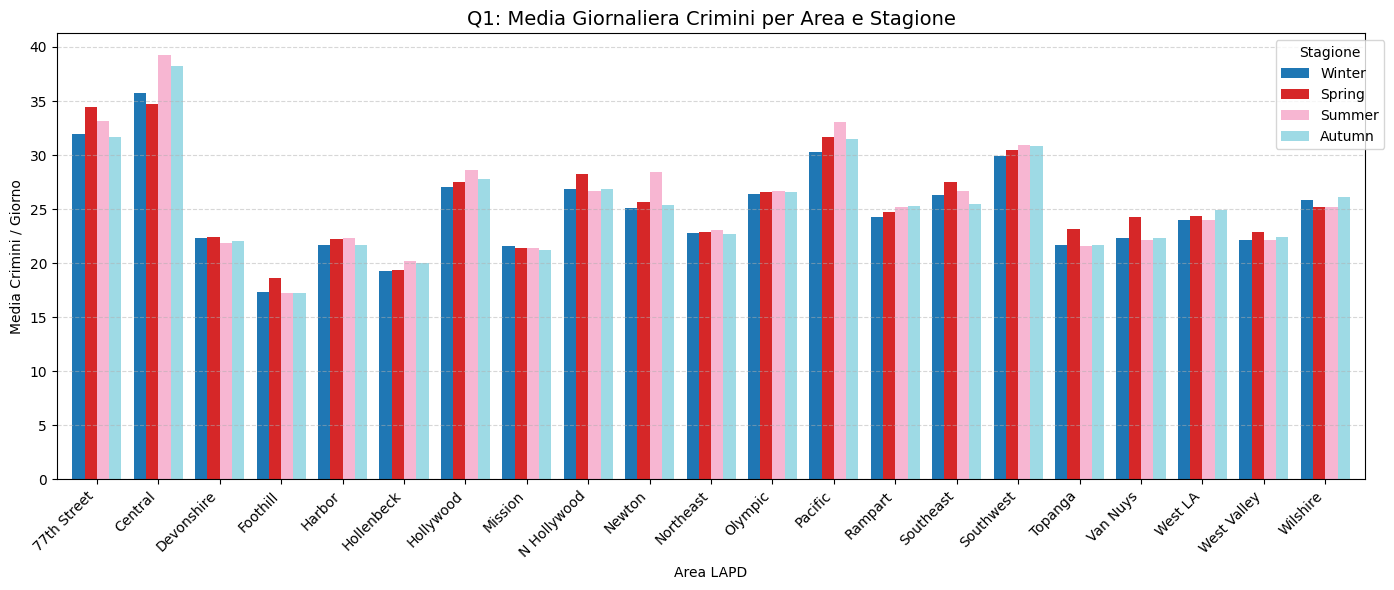


ANALISI: Aree con picco di criminalità stagionale (variazione >15%)

Distribuzione picchi per stagione:
   Summer: 9 aree (42.9%)
   Spring: 8 aree (38.1%)
   Autumn: 3 aree (14.3%)
   Winter: 1 aree (4.8%)


In [10]:
# Query per conteggio totale crimini per area/stagione
q1_total = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> group(columns: ["area_name", "season"])
    |> count()
'''

# Query per conteggio giorni unici per stagione (usando truncateTimeColumn)
q1_days = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> group(columns: ["season"])
    |> aggregateWindow(every: 1d, fn: count, createEmpty: false)
    |> group(columns: ["season"])
    |> count()
'''

start_time = time.time()
result_q1_total = query_api.query_data_frame(q1_total)
result_q1_days = query_api.query_data_frame(q1_days)
query_time = time.time() - start_time
print(f"Tempo query: {query_time:.2f}s")

if isinstance(result_q1_total, list):
    result_q1_total = pd.concat(result_q1_total)
if isinstance(result_q1_days, list):
    result_q1_days = pd.concat(result_q1_days)

if not result_q1_total.empty and not result_q1_days.empty:
    # Crea dizionario giorni per stagione
    days_per_season = dict(zip(result_q1_days['season'], result_q1_days['_value']))
    print(f"\nGiorni per stagione nel dataset:")
    for s, d in days_per_season.items():
        print(f"   {s}: {int(d)} giorni")
    
    # Calcola media giornaliera
    result_q1_total['daily_avg'] = result_q1_total.apply(
        lambda row: row['_value'] / days_per_season.get(row['season'], 1), axis=1
    )
    
    pivot_q1 = result_q1_total.pivot(index='area_name', columns='season', values='daily_avg')
    
    # Ordina colonne stagionali
    season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
    pivot_q1 = pivot_q1[[s for s in season_order if s in pivot_q1.columns]]
    
    # Grafico a barre
    fig, ax = plt.subplots(figsize=(14, 6))
    pivot_q1.plot(kind='bar', ax=ax, width=0.8, colormap='tab20')
    ax.set_title('Q1: Media Giornaliera Crimini per Area e Stagione', fontsize=14)
    ax.set_ylabel('Media Crimini / Giorno')
    ax.set_xlabel('Area LAPD')
    ax.legend(title='Stagione', bbox_to_anchor=(1.02, 1))
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    # Analisi: Quali aree mostrano un picco di criminalità stagionale?
    print("\n" + "=" * 60)
    print("ANALISI: Aree con picco di criminalità stagionale (variazione >15%)")
    print("=" * 60)
    
    seasonal_peaks = []
    for area in pivot_q1.index:
        max_val = pivot_q1.loc[area].max()
        min_val = pivot_q1.loc[area].min()
        variation = (max_val - min_val) / min_val * 100 if min_val > 0 else 0
        max_season = pivot_q1.loc[area].idxmax()
        min_season = pivot_q1.loc[area].idxmin()
        seasonal_peaks.append({
            'Area': area, 
            'Picco': max_season, 
            'Minimo': min_season,
            'Variazione %': variation
        })
    
    df_peaks = pd.DataFrame(seasonal_peaks).sort_values('Variazione %', ascending=False)
    
    # Mostra aree con variazione significativa
    significant = df_peaks[df_peaks['Variazione %'] > 15]
    if not significant.empty:
        for _, row in significant.iterrows():
            print(f"   {row['Area']}: picco in {row['Picco']}, minimo in {row['Minimo']} (+{row['Variazione %']:.1f}%)")
    
    # Riepilogo stagioni di picco
    print(f"\nDistribuzione picchi per stagione:")
    season_counts = df_peaks['Picco'].value_counts()
    for season, count in season_counts.items():
        print(f"   {season}: {count} aree ({count/len(df_peaks)*100:.1f}%)")
else:
    print("Nessun dato trovato")

Tempo query: 0.00s


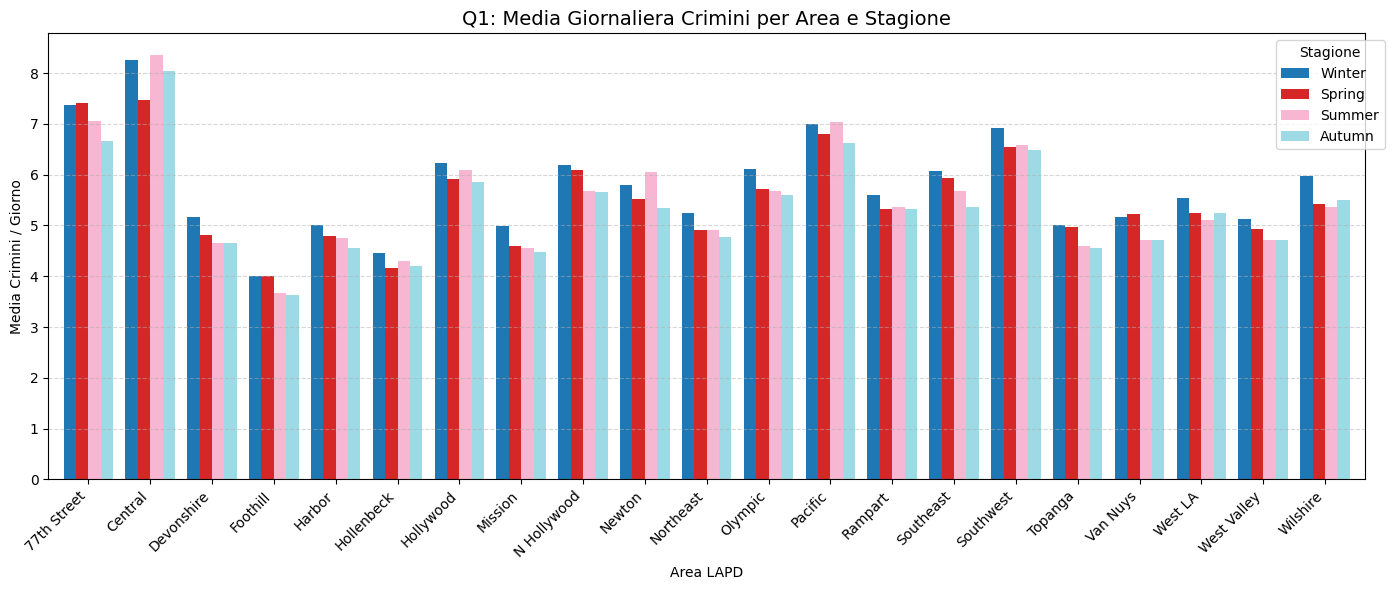

ANALISI: Aree con picco di criminalità stagionale

Distribuzione dei picchi:
- Winter  : 16 aree (76.2%)
- Summer  :  3 aree (14.3%)
- Spring  :  2 aree (9.5%)

Aree con picco del 5.0%:
- Wilshire -> Winter (+7.2%)
- Mission -> Winter (+7.2%)
- Devonshire -> Winter (+7.2%)
- Newton -> Summer (+6.7%)
- Northeast -> Winter (+5.8%)
- Olympic -> Winter (+5.6%)
- Van Nuys -> Spring (+5.5%)
- Southeast -> Winter (+5.4%)
- West Valley -> Winter (+5.1%)


In [29]:
# ==========================================
# QUERY 1 OTTIMIZZATA
# ==========================================
query = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")

    // 1. Raggruppa per Area e Stagione
    |> group(columns: ["area_name", "season"])

    // 2. Conta i crimini giornalieri (importante: createEmpty: true)
    |> aggregateWindow(every: 1d, fn: count, createEmpty: true)

    // 3. Riempie i giorni senza crimini con 0
    |> fill(value: 0)

    // 4. Calcola la media dei crimini giornalieri
    |> mean()

    // 5. Unifica in un'unica tabella per facilitare Pandas e mantiene colonne utili
    |> group()
    |> keep(columns: ["area_name", "season", "_value"])
'''

start_time = time.time()
# df = query_api.query_data_frame(query)
print(f"Tempo query: {time.time() - start_time:.2f}s")

# Gestione output lista (standard InfluxDB)
if isinstance(df, list):
    df = pd.concat(df)

# Rinomina la colonna valore
df = df.rename(columns={'_value': 'daily_avg'})

# Pivot per il grafico: Index=Area, Columns=Stagione
pivot_q1 = df.pivot(index='area_name', columns='season', values='daily_avg')

# Ordina le colonne delle stagioni in modo logico
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
pivot_q1 = pivot_q1[[s for s in season_order if s in pivot_q1.columns]]

# --- GRAFICO ---
fig, ax = plt.subplots(figsize=(14, 6))
pivot_q1.plot(kind='bar', ax=ax, width=0.8, colormap='tab20')
ax.set_title('Q1: Media Giornaliera Crimini per Area e Stagione', fontsize=14)
ax.set_ylabel('Media Crimini / Giorno')
ax.set_xlabel('Area LAPD')
ax.legend(title='Stagione', bbox_to_anchor=(1.02, 1))
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("ANALISI: Aree con picco di criminalità stagionale\n")

seasonal_peaks = []
for area in pivot_q1.index:
    # Recupera i valori della riga
    row_data = pivot_q1.loc[area]
    
    max_val = row_data.max()    # Valore del picco
    mean_val = row_data.mean()  # Valore medio annuale (baseline)
    
    # (Max - Media) / Media
    # Indica di quanto il picco supera la normalità
    peak_intensity = (max_val - mean_val) / mean_val * 100 
    
    max_season = row_data.idxmax()
    
    seasonal_peaks.append({
        'Area': area, 
        'Stagione Picco': max_season, 
        'Media Annuale': mean_val,
        'Valore Picco': max_val,
        'Intensità Picco %': peak_intensity
    })

df_peaks = pd.DataFrame(seasonal_peaks).sort_values('Intensità Picco %', ascending=False)

print("Distribuzione dei picchi:")
season_counts = df_peaks['Stagione Picco'].value_counts()
for season, count in season_counts.items():
    pct = count / len(df_peaks) * 100
    print(f"- {season:<8}: {count:>2} aree ({pct:.1f}%)")

# Aree con Picchi Rilevanti
soglia_picco = 5.0 
print(f"\nAree con picco del {soglia_picco}%:")

significant = df_peaks[df_peaks['Intensità Picco %'] > soglia_picco]

if not significant.empty:
    for _, row in significant.iterrows():
        print(f"- {row['Area']} -> {row['Stagione Picco']} (+{row['Intensità Picco %']:.1f}%)")
else:
    print("Nessuna area supera la soglia specificata.")

Q2: Distribuzione Day/Night per categoria (Luglio 2023)
Tempo query: 0.17s


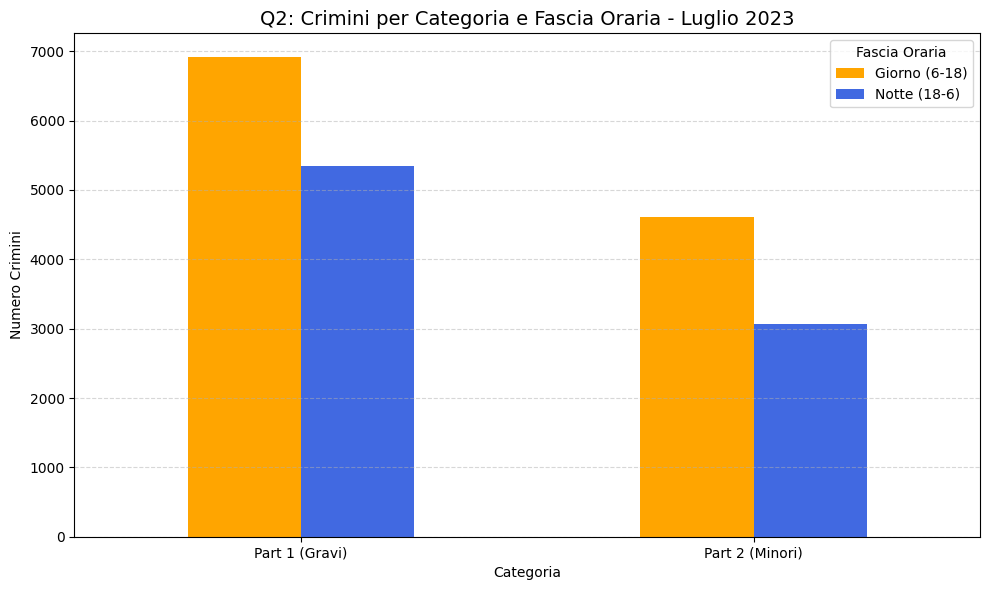


ANALISI: I crimini violenti sono maggiormente distribuiti di notte?

   Part 1 (Gravi):
      Diurni:   6,912 (56.4%)
      Notturni: 5,346 (43.6%)

   Part 2 (Minori):
      Diurni:   4,610 (60.0%)
      Notturni: 3,067 (40.0%)

------------------------------------------------------------
RISPOSTA:
   SÌ, i crimini violenti (Part 1) hanno una distribuzione notturna
   superiore rispetto ai crimini minori (Part 2).
   Differenza: +3.7 punti percentuali di notte


In [11]:
# =============================
# Q2: Distribuzione Part 1 vs Part 2 per Day/Night (Luglio 2023)
# =============================

print("=" * 60)
print("Q2: Distribuzione Day/Night per categoria (Luglio 2023)")
print("=" * 60)

q2 = f'''
from(bucket: "{bucket}")
    |> range(start: 2023-07-01T00:00:00Z, stop: 2023-07-31T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> group(columns: ["part", "time_period"])
    |> count()
'''

start_time = time.time()
result_q2 = query_api.query_data_frame(q2)
query_time = time.time() - start_time
print(f"Tempo query: {query_time:.2f}s")

if isinstance(result_q2, list):
    result_q2 = pd.concat(result_q2)

if not result_q2.empty:
    # Mapping per leggibilità
    result_q2['Part_Label'] = result_q2['part'].map({'1': 'Part 1 (Gravi)', '2': 'Part 2 (Minori)'})
    result_q2['Time_Label'] = result_q2['time_period'].map({'Day': 'Giorno (6-18)', 'Night': 'Notte (18-6)'})
    
    pivot_q2 = result_q2.pivot(index='Part_Label', columns='Time_Label', values='_value')
    
    # Grafico a barre
    fig, ax = plt.subplots(figsize=(10, 6))
    pivot_q2.plot(kind='bar', ax=ax, color=['#FFA500', '#4169E1'])
    ax.set_title('Q2: Crimini per Categoria e Fascia Oraria - Luglio 2023', fontsize=14)
    ax.set_ylabel('Numero Crimini')
    ax.set_xlabel('Categoria')
    ax.legend(title='Fascia Oraria')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Analisi dettagliata
    print("\n" + "=" * 60)
    print("ANALISI: I crimini violenti sono maggiormente distribuiti di notte?")
    print("=" * 60)
    
    # Calcolo percentuali
    analysis_data = []
    for part in pivot_q2.index:
        night = pivot_q2.loc[part, 'Notte (18-6)'] if 'Notte (18-6)' in pivot_q2.columns else 0
        day = pivot_q2.loc[part, 'Giorno (6-18)'] if 'Giorno (6-18)' in pivot_q2.columns else 0
        total = night + day
        night_pct = night / total * 100 if total > 0 else 0
        day_pct = day / total * 100 if total > 0 else 0
        analysis_data.append({
            'Categoria': part,
            'Giorno': int(day),
            'Notte': int(night),
            'Totale': int(total),
            '% Notte': night_pct
        })
        print(f"\n   {part}:")
        print(f"      Diurni:   {int(day):,} ({day_pct:.1f}%)")
        print(f"      Notturni: {int(night):,} ({night_pct:.1f}%)")
    
    # Confronto diretto
    part1_night_pct = analysis_data[0]['% Notte'] if 'Gravi' in analysis_data[0]['Categoria'] else analysis_data[1]['% Notte']
    part2_night_pct = analysis_data[1]['% Notte'] if 'Minori' in analysis_data[1]['Categoria'] else analysis_data[0]['% Notte']
    
    print("\n" + "-" * 60)
    print("RISPOSTA:")
    if part1_night_pct > part2_night_pct:
        diff = part1_night_pct - part2_night_pct
        print(f"   SÌ, i crimini violenti (Part 1) hanno una distribuzione notturna")
        print(f"   superiore rispetto ai crimini minori (Part 2).")
        print(f"   Differenza: +{diff:.1f} punti percentuali di notte")
    elif part1_night_pct < part2_night_pct:
        diff = part2_night_pct - part1_night_pct
        print(f"   NO, i crimini violenti (Part 1) hanno una distribuzione notturna")
        print(f"   inferiore rispetto ai crimini minori (Part 2).")
        print(f"   Differenza: -{diff:.1f} punti percentuali")
    else:
        print(f"   La distribuzione notturna è simile per entrambe le categorie.")
else:
    print("Nessun dato trovato")

In [ ]:
# =============================
# Q3: Giornata con max crimini violenti per Area
# =============================

print("=" * 60)
print("Q3: Giornata con massimo crimini violenti (Part 1) per Area")
print("=" * 60)

# Query: aggregazione giornaliera per area, poi selezioniamo il max
q3 = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["part"] == "1")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> aggregateWindow(every: 1d, fn: count, createEmpty: false)
    |> group(columns: ["area_name"])
    |> max()
'''

try:
    start_time = time.time()
    result_q3 = query_api.query_data_frame(q3)
    query_time = time.time() - start_time
    print(f"Tempo query: {query_time:.2f}s")
    
    if isinstance(result_q3, list):
        result_q3 = pd.concat(result_q3)
    
    if not result_q3.empty:
        # Prepara tabella
        display_q3 = result_q3[['area_name', '_time', '_value']].copy()
        display_q3['_time'] = pd.to_datetime(display_q3['_time'])
        display_q3['Data'] = display_q3['_time'].dt.date
        display_q3.columns = ['Area', '_time_full', 'Crimini Violenti', 'Data Picco']
        display_q3 = display_q3[['Area', 'Data Picco', 'Crimini Violenti']]
        display_q3 = display_q3.sort_values('Crimini Violenti', ascending=False)
        
        # Tabella formattata
        print("\n" + "=" * 55)
        print("TABELLA: Giornata con Max Crimini Violenti per Area")
        print("=" * 55)
        print(f"{'Area':<20} {'Data':<15} {'Conteggio':<10}")
        print("-" * 55)
        for _, row in display_q3.iterrows():
            print(f"{row['Area']:<20} {str(row['Data Picco']):<15} {int(row['Crimini Violenti']):<10}")
        print("=" * 55)
        
        # Analisi: In quali mesi si concentrano i picchi più elevati?
        print("\n" + "=" * 60)
        print("ANALISI: In quali mesi si concentrano i picchi più elevati?")
        print("=" * 60)
        
        display_q3['Mese'] = pd.to_datetime(display_q3['Data Picco']).dt.month_name()
        display_q3['Anno'] = pd.to_datetime(display_q3['Data Picco']).dt.year
        
        # Distribuzione per mese
        month_counts = display_q3['Mese'].value_counts()
        print("\nDistribuzione picchi per mese:")
        for month, count in month_counts.items():
            pct = count / len(display_q3) * 100
            bar = '█' * int(pct / 5)
            print(f"   {month:<12}: {count:2} aree ({pct:5.1f}%) {bar}")
        
        # Top 3 mesi con più picchi
        top_months = month_counts.head(3)
        print(f"\nI mesi con più picchi di crimini violenti sono:")
        for i, (month, count) in enumerate(top_months.items(), 1):
            print(f"   {i}. {month} ({count} aree)")
        
        # Distribuzione per anno
        print("\nDistribuzione per anno:")
        year_counts = display_q3['Anno'].value_counts().sort_index()
        for year, count in year_counts.items():
            print(f"   {year}: {count} aree hanno avuto il picco in questo anno")
            
    else:
        print("Nessun dato trovato")
        
except Exception as e:
    print(f"Errore: {e}")

Q3: Giornata con massimo crimini violenti (Part 1) per Area
Tempo query: 5.92s

TABELLA: Giornata con Max Crimini Violenti per Area
Area                 Data            Conteggio 
-------------------------------------------------------
Southwest            2023-08-07      51        
Wilshire             2020-05-31      40        
Mission              2020-11-09      29        
Devonshire           2022-02-06      21        
Topanga              2021-09-24      18        
Central              2020-05-30      16        
Foothill             2020-08-22      13        
Newton               2022-02-27      13        
Southeast            2022-03-19      12        
Rampart              2024-09-11      12        
Northeast            2023-11-12      12        
Harbor               2020-09-09      12        
Hollenbeck           2021-05-12      11        
West LA              2020-03-27      11        
West Valley          2024-10-13      11        
Hollywood            2022-02-19      10     

Q4: Età media vittime per categoria (Part) e anno
Tempo query: 11.53s

TABELLA: Età Media Vittime per Anno e Categoria
Anno       Part 1 (Gravi)       Part 2 (Minori)     
--------------------------------------------------
2020       39.8                 39.5                
2021       39.6                 39.6                
2022       39.5                 39.3                
2023       39.7                 39.5                
2024       38.6                 39.5                
2025       24.1                 23.2                


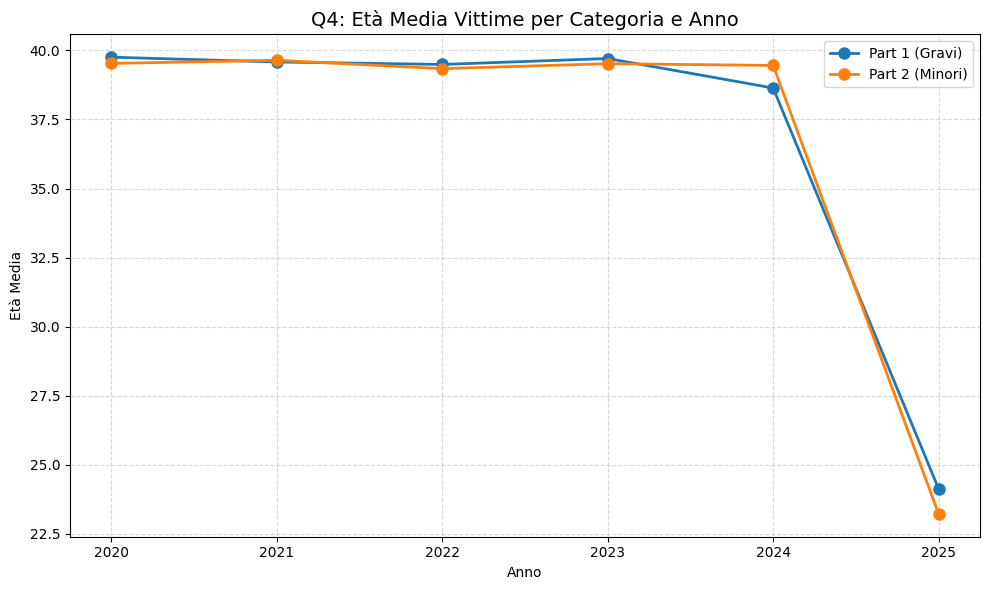


ANALISI:
   Part 1 (Gravi): età media diminuita di 15.6 anni (39.8 → 24.1)
   Part 2 (Minori): età media diminuita di 16.3 anni (39.5 → 23.2)


In [ ]:
# =============================
# Q4: Età media vittime per Categoria e Anno
# =============================

print("=" * 60)
print("Q4: Età media vittime per categoria (Part) e anno")
print("=" * 60)

# Query separata per ogni anno per evitare problemi di aggregazione
years = [2020, 2021, 2022, 2023, 2024, 2025]
results_q4 = []

start_time = time.time()

for year in years:
    q4_year = f'''
    from(bucket: "{bucket}")
        |> range(start: {year}-01-01T00:00:00Z, stop: {year}-12-31T23:59:59Z)
        |> filter(fn: (r) => r["_measurement"] == "crime_report")
        |> filter(fn: (r) => r["_field"] == "vict_age")
        |> filter(fn: (r) => r["_value"] > 0 and r["_value"] < 120)
        |> group(columns: ["part"])
        |> mean()
    '''
    
    try:
        result = query_api.query_data_frame(q4_year)
        if isinstance(result, list):
            result = pd.concat(result)
        if not result.empty:
            result['Year'] = year
            results_q4.append(result)
    except Exception as e:
        print(f"   Errore anno {year}: {e}")

query_time = time.time() - start_time
print(f"Tempo query: {query_time:.2f}s")

if results_q4:
    result_q4 = pd.concat(results_q4, ignore_index=True)
    result_q4['Part_Label'] = result_q4['part'].map({'1': 'Part 1 (Gravi)', '2': 'Part 2 (Minori)'})
    
    # Pivot con aggregazione per gestire eventuali duplicati
    pivot_q4 = result_q4.groupby(['Year', 'Part_Label'])['_value'].mean().unstack()
    
    # Tabella formattata
    print("\n" + "=" * 50)
    print("TABELLA: Età Media Vittime per Anno e Categoria")
    print("=" * 50)
    print(f"{'Anno':<10} {'Part 1 (Gravi)':<20} {'Part 2 (Minori)':<20}")
    print("-" * 50)
    for year in pivot_q4.index:
        p1 = pivot_q4.loc[year, 'Part 1 (Gravi)'] if 'Part 1 (Gravi)' in pivot_q4.columns else 0
        p2 = pivot_q4.loc[year, 'Part 2 (Minori)'] if 'Part 2 (Minori)' in pivot_q4.columns else 0
        print(f"{year:<10} {p1:<20.1f} {p2:<20.1f}")
    print("=" * 50)
    
    # Grafico a linee
    fig, ax = plt.subplots(figsize=(10, 6))
    for col in pivot_q4.columns:
        ax.plot(pivot_q4.index, pivot_q4[col], marker='o', linewidth=2, markersize=8, label=col)
    
    ax.set_title('Q4: Età Media Vittime per Categoria e Anno', fontsize=14)
    ax.set_xlabel('Anno')
    ax.set_ylabel('Età Media')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xticks(pivot_q4.index)
    plt.tight_layout()
    plt.show()
    
    # Analisi trend
    print("\nANALISI:")
    for col in pivot_q4.columns:
        first_year = pivot_q4[col].iloc[0]
        last_year = pivot_q4[col].dropna().iloc[-1]
        diff = last_year - first_year
        trend = "aumentata" if diff > 0 else "diminuita" if diff < 0 else "stabile"
        print(f"   {col}: età media {trend} di {abs(diff):.1f} anni ({first_year:.1f} → {last_year:.1f})")
        
else:
    print("Nessun dato trovato")

## Performance Check
Confrontiamo il tempo di esecuzione di una query globale vs una filtrata per stagione.

BENCHMARK: Confronto tempi query globale vs stagionale

Esecuzione benchmark...
   Query globale: 9.671s
   Query Winter: 2.389s
   Query Spring: 2.550s
   Query Summer: 2.329s
   Query Autumn: 2.516s

Risultati:
   Tempo globale: 9.671s
   Tempo medio stagionale: 2.446s
   Speedup filtro Season: 74.7%


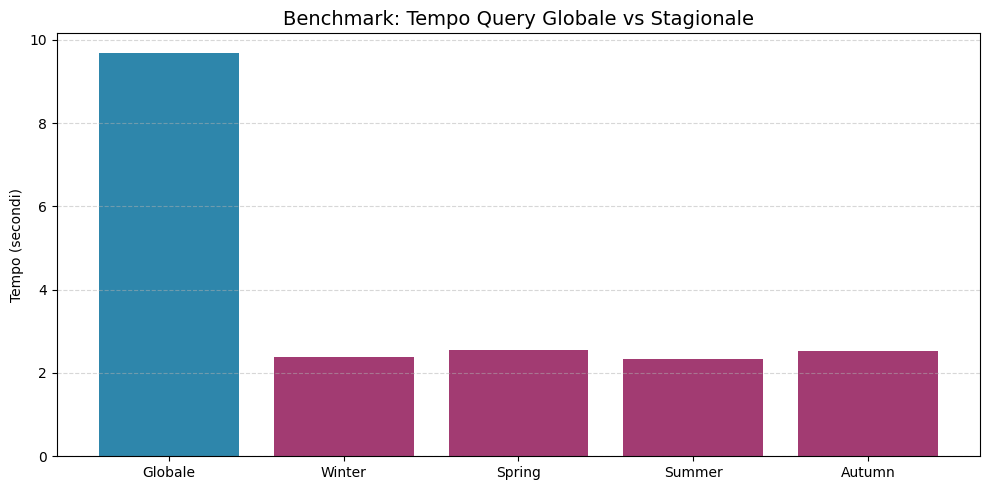

In [ ]:
# =============================
# BENCHMARK: Query Globale vs Stagionale
# =============================

print("=" * 60)
print("BENCHMARK: Confronto tempi query globale vs stagionale")
print("=" * 60)

def measure_query(season_filter=None):
    """Misura tempo di esecuzione query con/senza filtro stagione."""
    base_q = f'''
    from(bucket: "{bucket}")
        |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
        |> filter(fn: (r) => r["_measurement"] == "crime_report")
        |> filter(fn: (r) => r["_field"] == "dr_no")
    '''
    if season_filter:
        base_q += f'\n      |> filter(fn: (r) => r["season"] == "{season_filter}")'
    
    base_q += '\n      |> count()'
    
    start = time.time()
    query_api.query(base_q)
    return time.time() - start

# Esegui benchmark
print("\nEsecuzione benchmark...")

t_global = measure_query()
print(f"   Query globale: {t_global:.3f}s")

seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
seasonal_times = {}
for season in seasons:
    t = measure_query(season)
    seasonal_times[season] = t
    print(f"   Query {season}: {t:.3f}s")

avg_seasonal = np.mean(list(seasonal_times.values()))

print(f"\nRisultati:")
print(f"   Tempo globale: {t_global:.3f}s")
print(f"   Tempo medio stagionale: {avg_seasonal:.3f}s")

if t_global > avg_seasonal:
    speedup = (t_global - avg_seasonal) / t_global * 100
    print(f"   Speedup filtro Season: {speedup:.1f}%")
else:
    print(f"   Nessun speedup significativo (dati troppo piccoli o cache)")

# Grafico
fig, ax = plt.subplots(figsize=(10, 5))
times = [t_global] + list(seasonal_times.values())
labels = ['Globale'] + seasons
colors = ['#2E86AB'] + ['#A23B72']*4

ax.bar(labels, times, color=colors)
ax.set_title('Benchmark: Tempo Query Globale vs Stagionale', fontsize=14)
ax.set_ylabel('Tempo (secondi)')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

--- 
## 3. Analisi Avanzata: Clustering Incrementale

Utilizziamo un **algoritmo di clustering incrementale** (`river.cluster.KMeans`) per raggruppare le aree in base ai pattern di criminalità.

**Variabili di aggregazione**: Area, Stagione, Anno  
**Feature**: Numero crimini, % con arma, % notturni, % violenti (Part 1)

**Obiettivo**: Individuare aree simili nei pattern di criminalità e verificare se i cluster cambiano significativamente tra 2020 e 2025.

In [ ]:
# =============================
# CLUSTERING INCREMENTALE - Estrazione Feature
# =============================

print("=" * 60)
print("CLUSTERING INCREMENTALE: Estrazione feature da InfluxDB")
print("=" * 60)

# Query totale crimini per Area/Season/Year
q_total = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crime_report")
  |> filter(fn: (r) => r["_field"] == "dr_no")
  |> group(columns: ["area_name", "season"])
  |> aggregateWindow(every: 1y, fn: count, createEmpty: false)
'''

# Query crimini con arma
q_weapon = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crime_report")
  |> filter(fn: (r) => r["_field"] == "dr_no")
  |> filter(fn: (r) => r["weapon_flag"] == "True")
  |> group(columns: ["area_name", "season"])
  |> aggregateWindow(every: 1y, fn: count, createEmpty: false)
'''

# Query crimini notturni
q_night = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crime_report")
  |> filter(fn: (r) => r["_field"] == "dr_no")
  |> filter(fn: (r) => r["time_period"] == "Night")
  |> group(columns: ["area_name", "season"])
  |> aggregateWindow(every: 1y, fn: count, createEmpty: false)
'''

# Query crimini violenti (Part 1)
q_violent = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crime_report")
  |> filter(fn: (r) => r["_field"] == "dr_no")
  |> filter(fn: (r) => r["part"] == "1")
  |> group(columns: ["area_name", "season"])
  |> aggregateWindow(every: 1y, fn: count, createEmpty: false)
'''

print("Esecuzione query per feature clustering...")
start_time = time.time()

df_total = query_api.query_data_frame(q_total)
df_weapon = query_api.query_data_frame(q_weapon)
df_night = query_api.query_data_frame(q_night)
df_violent = query_api.query_data_frame(q_violent)

print(f"Query completate in {time.time() - start_time:.2f}s")

# Concatena se lista
if isinstance(df_total, list):
    df_total = pd.concat(df_total)
if isinstance(df_weapon, list):
    df_weapon = pd.concat(df_weapon)
if isinstance(df_night, list):
    df_night = pd.concat(df_night)
if isinstance(df_violent, list):
    df_violent = pd.concat(df_violent)

# Prepara DataFrame
def prepare_df(df_q, col_name):
    df_q = df_q.copy()
    df_q['Year'] = pd.to_datetime(df_q['_time']).dt.year
    df_q = df_q.rename(columns={'_value': col_name})
    return df_q[['area_name', 'season', 'Year', col_name]]

df_total = prepare_df(df_total, 'total')
df_weapon = prepare_df(df_weapon, 'weapon')
df_night = prepare_df(df_night, 'night')
df_violent = prepare_df(df_violent, 'violent')

# Merge
df_features = df_total.merge(df_weapon, on=['area_name', 'season', 'Year'], how='left')
df_features = df_features.merge(df_night, on=['area_name', 'season', 'Year'], how='left')
df_features = df_features.merge(df_violent, on=['area_name', 'season', 'Year'], how='left')
df_features = df_features.fillna(0)

# Calcola percentuali
df_features['pct_weapon'] = df_features['weapon'] / df_features['total'] * 100
df_features['pct_night'] = df_features['night'] / df_features['total'] * 100
df_features['pct_violent'] = df_features['violent'] / df_features['total'] * 100

# Ordina per simulare stream temporale
df_features = df_features.sort_values(['Year', 'season', 'area_name']).reset_index(drop=True)

print(f"\nFeature estratte: {len(df_features)} record (Area x Season x Year)")
print(f"   Aree: {df_features['area_name'].nunique()}")
print(f"   Stagioni: {df_features['season'].nunique()}")
print(f"   Anni: {sorted(df_features['Year'].unique())}")
print("\nPrimi 10 record:")
print(df_features.head(10))

CLUSTERING INCREMENTALE: Estrazione feature da InfluxDB
Esecuzione query per feature clustering...
Query completate in 47.69s

Feature estratte: 536 record (Area x Season x Year)
   Aree: 21
   Stagioni: 4
   Anni: [np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Primi 10 record:
     area_name  season  Year  total  weapon  night  violent  pct_weapon  \
0  77th Street  Autumn  2021   3261    1697   1441     1851   52.039252   
1      Central  Autumn  2021   2705    1224   1158     1598   45.249538   
2   Devonshire  Autumn  2021   1875     534    661     1083   28.480000   
3     Foothill  Autumn  2021   1670     622    680      913   37.245509   
4       Harbor  Autumn  2021   2231     793   1015     1278   35.544599   
5   Hollenbeck  Autumn  2021   1844     675    798     1074   36.605206   
6    Hollywood  Autumn  2021   2530    1156   1096     1514   45.691700   
7      Mission  Autumn  2021   1999     656    843     1186   32.816408   
8  N Hollyw

CLUSTERING INCREMENTALE con river.cluster.KMeans

Statistiche feature (per normalizzazione):
        total  pct_weapon  pct_night  pct_violent
mean  2050.25     2508.43    3304.58      4875.95
std   1022.42    10275.41   13245.03     20536.41

Training incrementale in corso...
   Processati 100/536 record...
   Processati 200/536 record...
   Processati 300/536 record...
   Processati 400/536 record...
   Processati 500/536 record...

Clustering completato in 0.03s

CENTROIDI DEI CLUSTER
           total  pct_weapon  pct_night  pct_violent
Cluster                                             
0        2334.30       29.75      38.34        56.08
1         538.18     4002.56    5468.26      7612.48
2           1.48    38200.00   49646.00     74978.00
3        3075.94       38.39      39.37        57.07

Interpretazione Cluster:
   Cluster 0: Volume ALTO, Violenza BASSO, Armi BASSO, Notturni BASSO
   Cluster 1: Volume BASSO, Violenza ALTO, Armi ALTO, Notturni ALTO
   Cluster 2: Volume BASS

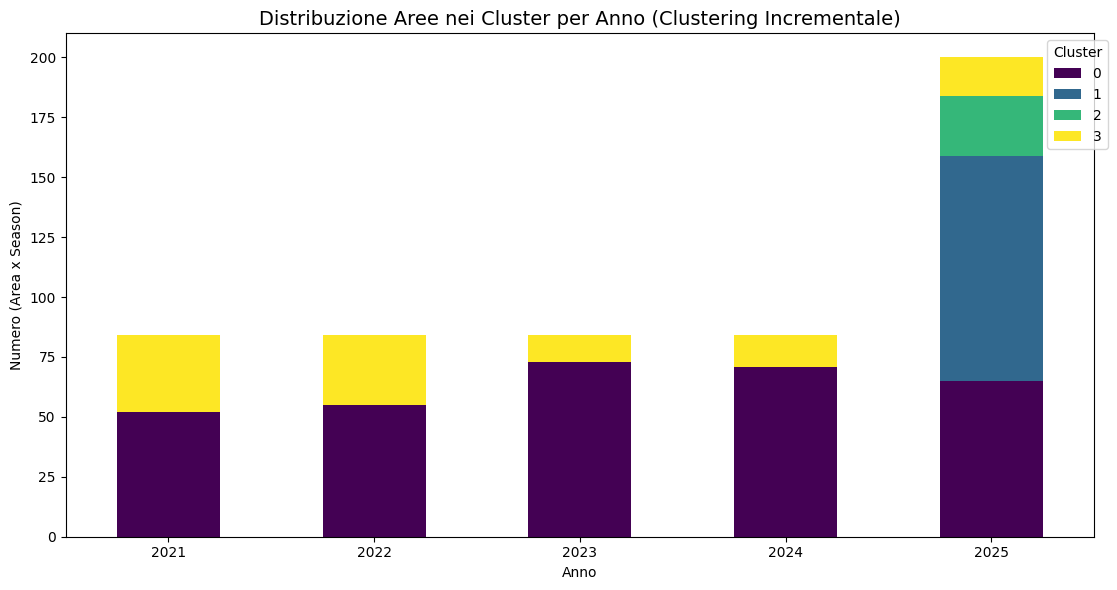

In [16]:
# =============================
# CLUSTERING INCREMENTALE con River
# =============================

print("=" * 60)
print("CLUSTERING INCREMENTALE con river.cluster.KMeans")
print("=" * 60)

# Feature per clustering (normalizzate manualmente per river)
feature_cols = ['total', 'pct_weapon', 'pct_night', 'pct_violent']
n_clusters = 4

# Calcola statistiche per normalizzazione incrementale
feature_stats = df_features[feature_cols].agg(['mean', 'std'])
print("\nStatistiche feature (per normalizzazione):")
print(feature_stats.round(2))

# Funzione di normalizzazione
def normalize_row(row, stats=feature_stats):
    return {col: (row[col] - stats[col]['mean']) / stats[col]['std'] 
            for col in feature_cols}

# Inizializza modello KMeans incrementale da river
incremental_kmeans = cluster.KMeans(n_clusters=n_clusters, seed=42)

# Lista per salvare assegnazioni
cluster_assignments = []

print("\nTraining incrementale in corso...")
start_time = time.time()

# Simula stream: processa un record alla volta
for idx, row in df_features.iterrows():
    # Normalizza features
    x = normalize_row(row)
    
    # Learn e predict (incrementale)
    incremental_kmeans.learn_one(x)
    cluster_id = incremental_kmeans.predict_one(x)
    
    cluster_assignments.append({
        'area_name': row['area_name'],
        'season': row['season'],
        'Year': row['Year'],
        'total': row['total'],
        'pct_weapon': row['pct_weapon'],
        'pct_night': row['pct_night'],
        'pct_violent': row['pct_violent'],
        'Cluster': cluster_id
    })
    
    if (idx + 1) % 100 == 0:
        print(f"   Processati {idx + 1}/{len(df_features)} record...")

df_clustered = pd.DataFrame(cluster_assignments)
print(f"\nClustering completato in {time.time() - start_time:.2f}s")

# === ANALISI CENTROIDI ===
print("\n" + "=" * 60)
print("CENTROIDI DEI CLUSTER")
print("=" * 60)

centroids = df_clustered.groupby('Cluster')[feature_cols].mean()
print(centroids.round(2).to_string())

# Interpretazione cluster
print("\nInterpretazione Cluster:")
for c_id in centroids.index:
    row = centroids.loc[c_id]
    crime_level = "ALTO" if row['total'] > centroids['total'].median() else "BASSO"
    violent_level = "ALTO" if row['pct_violent'] > centroids['pct_violent'].median() else "BASSO"
    weapon_level = "ALTO" if row['pct_weapon'] > centroids['pct_weapon'].median() else "BASSO"
    night_level = "ALTO" if row['pct_night'] > centroids['pct_night'].median() else "BASSO"
    print(f"   Cluster {c_id}: Volume {crime_level}, Violenza {violent_level}, Armi {weapon_level}, Notturni {night_level}")

# === DISTRIBUZIONE PER ANNO ===
print("\n" + "=" * 60)
print("DISTRIBUZIONE CLUSTER PER ANNO")
print("=" * 60)

cluster_by_year = df_clustered.groupby(['Year', 'Cluster']).size().unstack(fill_value=0)
print(cluster_by_year)

# Grafico distribuzione per anno
fig, ax = plt.subplots(figsize=(12, 6))
cluster_by_year.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_title('Distribuzione Aree nei Cluster per Anno (Clustering Incrementale)', fontsize=14)
ax.set_ylabel('Numero (Area x Season)')
ax.set_xlabel('Anno')
ax.legend(title='Cluster', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

CONFRONTO CLUSTER: 2020 vs 2025

Anni disponibili nel dataset: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Confronto tra 2021 e 2025

Record 2021: 84
Record 2025: 200

Distribuzione percentuale per cluster:
Cluster    2021            2025            Variazione     
-------------------------------------------------------
0            61.9%          32.5%        -29.4%
1             0.0%          47.0%        + 47.0%
2             0.0%          12.5%        + 12.5%
3            38.1%           8.0%        -30.1%
-------------------------------------------------------
Variazione totale assoluta: 119.0%

ANALISI CAMBIO CLUSTER PER AREA

   Aree che hanno cambiato cluster: 18 (85.7%)
   Aree con cluster stabile: 3 (14.3%)

   Dettaglio aree che hanno cambiato cluster:
      77th Street: Cluster 3 → Cluster 2
      Devonshire: Cluster 0 → Cluster 1
      Foothill: Cluster 0 → Cluster 1
      Harbor: Cluster 0 → Cluster 1
      Hollenbeck: Cluster 0 → Clus

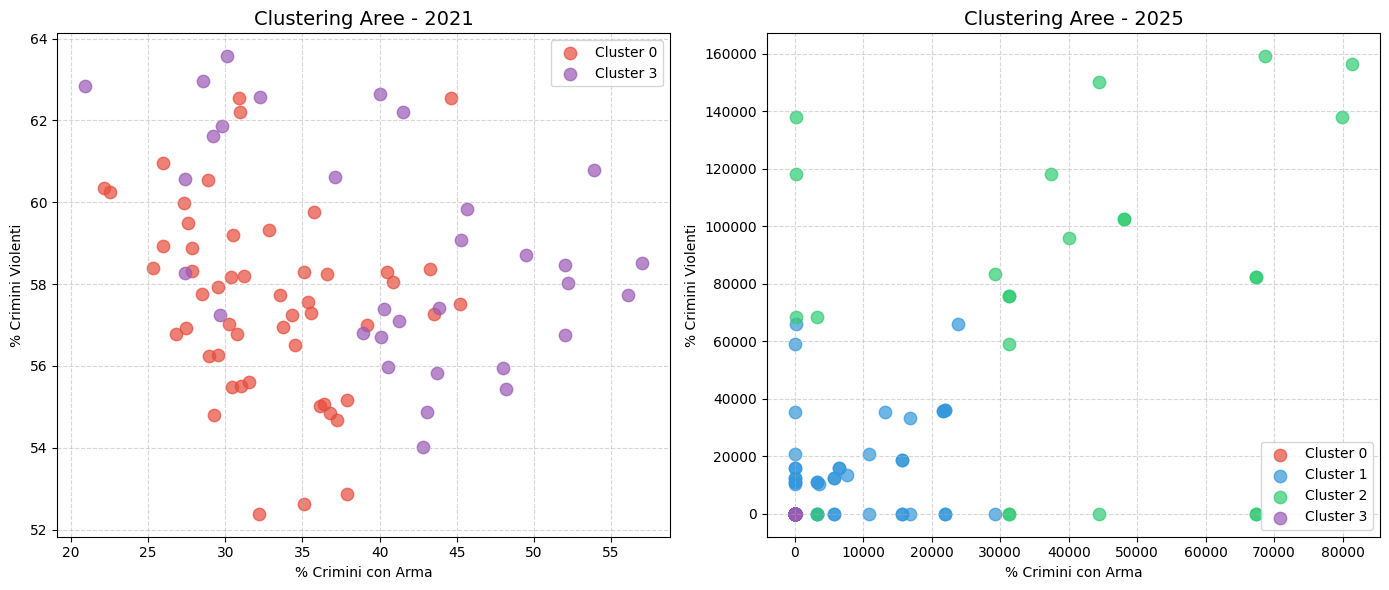


CONCLUSIONE: I cluster cambiano significativamente tra 2021 e 2025?

   SÌ, si osserva un cambiamento SIGNIFICATIVO nella distribuzione dei cluster.
   La variazione totale assoluta è del 119.0%.

   Possibili cause:
   - Cambiamento nei pattern di criminalità post-pandemia
   - Evoluzione nelle politiche di sicurezza per area
   - Shift demografici nelle diverse aree di Los Angeles



In [17]:
# =============================
# CONFRONTO 2020 vs 2025: I cluster cambiano significativamente?
# =============================

print("=" * 60)
print("CONFRONTO CLUSTER: 2020 vs 2025")
print("=" * 60)

# Verifica anni disponibili
available_years = sorted(df_clustered['Year'].unique())
print(f"\nAnni disponibili nel dataset: {available_years}")

# Seleziona gli anni per il confronto (primo e ultimo disponibile)
year_start = available_years[0]
year_end = available_years[-1]

print(f"Confronto tra {year_start} e {year_end}")

# Filtra dati per gli anni selezionati
df_start = df_clustered[df_clustered['Year'] == year_start].copy()
df_end = df_clustered[df_clustered['Year'] == year_end].copy()

print(f"\nRecord {year_start}: {len(df_start)}")
print(f"Record {year_end}: {len(df_end)}")

if len(df_start) == 0 or len(df_end) == 0:
    print("\nDati insufficienti per il confronto tra anni.")
else:
    # Distribuzione cluster per anno
    dist_start = df_start['Cluster'].value_counts().sort_index()
    dist_end = df_end['Cluster'].value_counts().sort_index()

    # Allinea gli indici
    all_clusters = sorted(set(dist_start.index) | set(dist_end.index))
    dist_start = dist_start.reindex(all_clusters, fill_value=0)
    dist_end = dist_end.reindex(all_clusters, fill_value=0)

    print(f"\nDistribuzione percentuale per cluster:")
    print(f"{'Cluster':<10} {str(year_start):<15} {str(year_end):<15} {'Variazione':<15}")
    print("-" * 55)

    total_start = len(df_start)
    total_end = len(df_end)
    total_variation = 0

    for c in all_clusters:
        pct_start = (dist_start[c] / total_start * 100) if total_start > 0 else 0
        pct_end = (dist_end[c] / total_end * 100) if total_end > 0 else 0
        variation = pct_end - pct_start
        total_variation += abs(variation)
        sign = "+" if variation > 0 else ""
        print(f"{c:<10} {pct_start:>6.1f}%        {pct_end:>6.1f}%        {sign}{variation:>5.1f}%")

    print("-" * 55)
    print(f"Variazione totale assoluta: {total_variation:.1f}%")

    # === ANALISI PER AREA ===
    print("\n" + "=" * 60)
    print("ANALISI CAMBIO CLUSTER PER AREA")
    print("=" * 60)

    # Confronta cluster medio per area tra anni
    area_cluster_start = df_start.groupby('area_name')['Cluster'].agg(lambda x: x.mode()[0] if len(x) > 0 else -1)
    area_cluster_end = df_end.groupby('area_name')['Cluster'].agg(lambda x: x.mode()[0] if len(x) > 0 else -1)

    # Merge
    area_comparison = pd.DataFrame({
        f'Cluster_{year_start}': area_cluster_start,
        f'Cluster_{year_end}': area_cluster_end
    }).dropna()

    if len(area_comparison) > 0:
        area_comparison['Changed'] = area_comparison[f'Cluster_{year_start}'] != area_comparison[f'Cluster_{year_end}']

        changed_areas = area_comparison[area_comparison['Changed']]
        unchanged_areas = area_comparison[~area_comparison['Changed']]

        print(f"\n   Aree che hanno cambiato cluster: {len(changed_areas)} ({len(changed_areas)/len(area_comparison)*100:.1f}%)")
        print(f"   Aree con cluster stabile: {len(unchanged_areas)} ({len(unchanged_areas)/len(area_comparison)*100:.1f}%)")

        if len(changed_areas) > 0:
            print(f"\n   Dettaglio aree che hanno cambiato cluster:")
            for area, row in changed_areas.iterrows():
                print(f"      {area}: Cluster {int(row[f'Cluster_{year_start}'])} → Cluster {int(row[f'Cluster_{year_end}'])}")
    else:
        print("\n   Nessuna area presente in entrambi gli anni per il confronto.")

    # === SCATTER PLOT ===
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6', '#F39C12']

    for idx, (year, df_year) in enumerate([(year_start, df_start), (year_end, df_end)]):
        ax = axes[idx]
        
        for c_id in sorted(df_year['Cluster'].unique()):
            data = df_year[df_year['Cluster'] == c_id]
            ax.scatter(data['pct_weapon'], data['pct_violent'], 
                       c=colors[c_id % len(colors)], label=f'Cluster {c_id}', s=80, alpha=0.7)
        
        ax.set_xlabel('% Crimini con Arma')
        ax.set_ylabel('% Crimini Violenti')
        ax.set_title(f'Clustering Aree - {year}', fontsize=14)
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    # === CONCLUSIONE ===
    print("\n" + "=" * 60)
    print(f"CONCLUSIONE: I cluster cambiano significativamente tra {year_start} e {year_end}?")
    print("=" * 60)

    if total_variation > 20:
        print(f"""
   SÌ, si osserva un cambiamento SIGNIFICATIVO nella distribuzione dei cluster.
   La variazione totale assoluta è del {total_variation:.1f}%.
   
   Possibili cause:
   - Cambiamento nei pattern di criminalità post-pandemia
   - Evoluzione nelle politiche di sicurezza per area
   - Shift demografici nelle diverse aree di Los Angeles
""")
    elif total_variation > 10:
        print(f"""
   Si osserva un cambiamento MODERATO nella distribuzione dei cluster.
   La variazione totale assoluta è del {total_variation:.1f}%.
   
   Alcune aree hanno modificato il loro profilo di criminalità,
   ma la maggior parte mantiene pattern simili.
""")
    else:
        print(f"""
   NO, i cluster rimangono sostanzialmente STABILI tra {year_start} e {year_end}.
   La variazione totale assoluta è solo del {total_variation:.1f}%.
   
   I pattern di criminalità per area sono rimasti consistenti nel tempo.
""")

In [ ]:
# =============================
# CHIUSURA E RIEPILOGO
# =============================

client.close()

print("=" * 70)
print("RIEPILOGO ANALISI CRIMINI LOS ANGELES (2020-2025)")
print("=" * 70)

print("""
PUNTO 1 - CARICAMENTO DATI:
   - Schema: 7 TAG (area_name, area_id, district, part, weapon_flag, season, time_period)
   - Fields: dr_no, lat, lon, vict_sex, vict_age, vict_descent, crime_cd, crime_desc, date_rptd
   - Timestamp: precisione microsecondo per unicità record
   - Filtri: coordinate nulle, date > Nov 2025, Crm Cd nullo
   - Sistema Alerting: soglie Warning (+5%) e Alarm (+10%) sulla media storica
     - Totale crimini giornalieri
     - Crimini violenti (Part 1)
     - Percentuale crimini con arma

PUNTO 2 - INTERROGAZIONI ANALITICHE:
   Q1: Media giornaliera crimini per Area/Stagione + analisi picchi stagionali
   Q2: Distribuzione Day/Night per categoria (mese a scelta) + risposta domanda
   Q3: Giornata picco crimini violenti per Area + analisi mesi
   Q4: Età media vittime per categoria/anno + trend temporale

PUNTO 3 - CLUSTERING INCREMENTALE:
   - Algoritmo: river.cluster.KMeans (incrementale)
   - Aggregazione: Area × Stagione × Anno
   - Feature: totale crimini, % arma, % notte, % violenti
   - Confronto 2020 vs 2025 con analisi cambiamento cluster
""")

print("=" * 70)
print("Notebook completato - Connessione chiusa")